# Challenge: identifying fraud

You work at a bank as a data scientist and have received the following dataset to analyze:

In [61]:
import pandas as pd

# criando um DataFrame com 30 transações aleatórias
df = pd.DataFrame({
    'ID da transação': range(1, 31),
    'Valor da transação': [100, 200, 150, 500, 300, 913, 250, 400, 200, 150,
                           200, 200, 400, 300, 150, 301, 805, 300, 400, 250,
                           150, 100, 500, 600, 200, 350, 100, 250, 800, 250],
    'Data da transação': pd.date_range(start='2022-01-01', end='2022-01-30', freq='D'),
    'Local da transação': ['São Paulo, Brasil', 'Rio de Janeiro, Brasil', 'Belo Horizonte, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'Nova Iorque, EUA', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'Rio de Janeiro, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'São Paulo, Brasil', 'Los Angeles, EUA', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil', 'São Paulo, Brasil',
                           'São Paulo, Brasil', 'São Paulo, Brasil', 'Miami, EUA', 'São Paulo, Brasil']
})

It has been reported that this dataset contains potential instances of fraud, which can be identified by looking for outliers in the “transaction value” column—essentially, a fraudulent transaction would appear as an outlier.

Your task is to build a function that takes two parameters: the column you wish to analyze for outliers and the DataFrame in question. The goal is to create a reusable function that can be applied to other columns or different DataFrames in future analyses. The method to be implemented for identifying these outliers is the interquartile range (IQR) approach.

In [62]:
df.describe()

,ID da transação,Valor da transação,Data da transação
count,30.000000,30.000000,30
mean,15.500000,325.633333,2022-01-15 12:00:00
min,1.000000,100.000000,2022-01-01 00:00:00
25%,8.250000,200.000000,2022-01-08 06:00:00
50%,15.500000,250.000000,2022-01-15 12:00:00
75%,22.750000,400.000000,2022-01-22 18:00:00
max,30.000000,913.000000,2022-01-30 00:00:00
std,8.803408,214.442579,NaN


<Axes: xlabel='Valor da transação'>

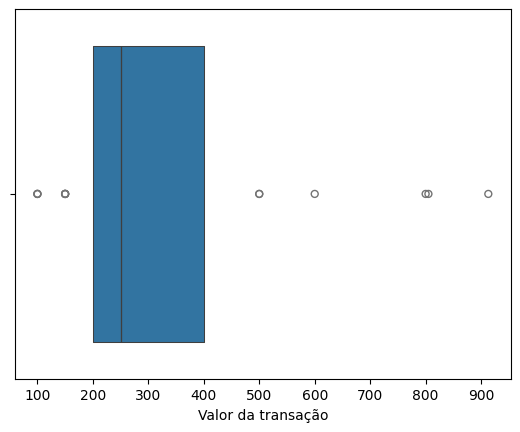

In [63]:
import seaborn as sns

sns.boxenplot(x=df['Valor da transação'])

In [64]:
def calc_outliers(column, dataframe):

  # calculate the IQR and define the threshold for outliers
  Q1 = dataframe[column].quantile(.25)
  Q3 = dataframe[column].quantile(.75)
  IQR = Q3 - Q1

  lower_limit = Q1 - 1.5 * IQR
  upper_limit = Q3 + 1.5 * IQR

  # identifying outliers
  outliers = (dataframe[column] < lower_limit) | (dataframe[column] > upper_limit)


  # returning the outliers
  return dataframe[outliers]

In [65]:
print(calc_outliers('Valor da transação', df))

    ID da transação  Valor da transação Data da transação Local da transação
5                 6                 913        2022-01-06   Nova Iorque, EUA
16               17                 805        2022-01-17   Los Angeles, EUA
28               29                 800        2022-01-29         Miami, EUA
